In [19]:
# Step 1: Load and filter data
import pandas as pd

# Read the whole file
df = pd.read_csv("city_temperature.csv")

df = df[(df["Country"] == "Algeria") & (df["City"] == "Algiers")]

print("Shape after filtering:", df.shape)
print(df.head())

/var/folders/fd/f3cwstnn6f34m9bld_42lb5r0000gn/T/ipykernel_2654/2635605802.py:5: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("city_temperature.csv")


Shape after filtering: (9266, 8)
   Region  Country State     City  Month  Day  Year  AvgTemperature
0  Africa  Algeria   NaN  Algiers      1    1  1995            64.2
1  Africa  Algeria   NaN  Algiers      1    2  1995            49.4
2  Africa  Algeria   NaN  Algiers      1    3  1995            48.8
3  Africa  Algeria   NaN  Algiers      1    4  1995            46.4
4  Africa  Algeria   NaN  Algiers      1    5  1995            47.9


In [20]:
# Step 2: Create a proper datetime column
df["date"] = pd.to_datetime(
    dict(year=df["Year"], month=df["Month"], day=df["Day"]),
    errors="coerce"
)


In [21]:

df = df.dropna(subset=["date"])

print(df[["Year","Month","Day","date"]].head())

   Year  Month  Day       date
0  1995      1    1 1995-01-01
1  1995      1    2 1995-01-02
2  1995      1    3 1995-01-03
3  1995      1    4 1995-01-04
4  1995      1    5 1995-01-05


In [22]:
# Step 3: Check missing values across all columns
print("Missing values in each column:")
print(df.isna().sum())

print("\nTotal rows before cleaning:", len(df))

Missing values in each column:
Region               0
Country              0
State             9266
City                 0
Month                0
Day                  0
Year                 0
AvgTemperature       0
date                 0
dtype: int64

Total rows before cleaning: 9266


In [23]:
#  Drop State (all NaN) and Region/Country/City (constant after filtering)
df = df.drop(columns=["State", "Region", "Country", "City"])

print("Remaining columns:", df.columns.tolist())
print(df.head())

Remaining columns: ['Month', 'Day', 'Year', 'AvgTemperature', 'date']
   Month  Day  Year  AvgTemperature       date
0      1    1  1995            64.2 1995-01-01
1      1    2  1995            49.4 1995-01-02
2      1    3  1995            48.8 1995-01-03
3      1    4  1995            46.4 1995-01-04
4      1    5  1995            47.9 1995-01-05


In [24]:
# Step 4: Clean AvgTemperature
import numpy as np

# Count how many -99 values exist
neg99_count = (df["AvgTemperature"] == -99).sum()
print("Number of -99 values:", neg99_count)



Number of -99 values: 35


In [25]:
# Replace -99 with NaN
df["AvgTemperature"] = df["AvgTemperature"].replace(-99, np.nan)



In [26]:
# Interpolate missing values along the time index
df = df.sort_values("date").set_index("date")
df["AvgTemperature"] = df["AvgTemperature"].interpolate(limit_direction="both")

# Check if any NaN remain
print("Remaining NaN after interpolation:", df["AvgTemperature"].isna().sum())

# Show first rows
print(df.head())

Remaining NaN after interpolation: 0
            Month  Day  Year  AvgTemperature
date                                        
1995-01-01      1    1  1995            64.2
1995-01-02      1    2  1995            49.4
1995-01-03      1    3  1995            48.8
1995-01-04      1    4  1995            46.4
1995-01-05      1    5  1995            47.9


In [27]:
# Step 5: Resample to monthly average
monthly = df["AvgTemperature"].resample("MS").mean().to_frame(name="AvgTemperature")

print("Monthly date range:", monthly.index.min().date(), "→", monthly.index.max().date())
print("Number of monthly points:", len(monthly))
print(monthly.head())



Monthly date range: 1995-01-01 → 2020-05-01
Number of monthly points: 305
            AvgTemperature
date                      
1995-01-01       51.419355
1995-02-01       54.800000
1995-03-01       55.000000
1995-04-01       57.193333
1995-05-01       67.409677


Naive Forecast

In [28]:
# Part 1: Train/Test Split + Naive Forecast
import numpy as np

# Series values and dates from the cleaned monthly dataset
y = monthly["AvgTemperature"].values
dates = monthly.index

# Split: last 24 months reserved for testing
test_months = 24
y_train, y_test = y[:-test_months], y[-test_months:]
dates_train, dates_test = dates[:-test_months], dates[-test_months:]

print("Train size:", len(y_train))
print("Test size :", len(y_test))

# Naive forecast = repeat the last observed value from training
naive_forecast = np.full_like(y_test, fill_value=y_train[-1])

print("Last observed value (used for naive forecast):", y_train[-1])
print("First 5 naive predictions:", naive_forecast[:5])

Train size: 281
Test size : 24
Last observed value (used for naive forecast): 63.42580645161291
First 5 naive predictions: [63.42580645 63.42580645 63.42580645 63.42580645 63.42580645]


In [29]:
# Part 2: Evaluate Naive Forecast
import numpy as np

# Define error metrics
def mae(actual, predicted):
    return np.mean(np.abs(actual - predicted))

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

def mape(actual, predicted):
    return np.mean(np.abs((actual - predicted) / actual)) * 100

# Calculate metrics for Naive forecast
print("=== Naive Forecast Evaluation ===")
print("MAE :", round(mae(y_test, naive_forecast), 3))
print("RMSE:", round(rmse(y_test, naive_forecast), 3))
print("MAPE:", round(mape(y_test, naive_forecast), 3), "%")

=== Naive Forecast Evaluation ===
MAE : 8.918
RMSE: 10.259
MAPE: 13.633 %


Seasonal Naive Forecast

In [30]:
#  Seasonal Naive Forecast
s = 12  # seasonality = 12 months (1 year)

seasonal_naive_forecast = []
for i in range(len(y_test)):
    idx = len(y_train) + i
    seasonal_naive_forecast.append(y[idx - s])
seasonal_naive_forecast = np.array(seasonal_naive_forecast)

# Evaluate Seasonal Naive
print("=== Seasonal Naive Forecast Evaluation ===")
print("MAE :", round(mae(y_test, seasonal_naive_forecast), 3))
print("RMSE:", round(rmse(y_test, seasonal_naive_forecast), 3))
print("MAPE:", round(mape(y_test, seasonal_naive_forecast), 3), "%")

=== Seasonal Naive Forecast Evaluation ===
MAE : 2.246
RMSE: 2.506
MAPE: 3.539 %


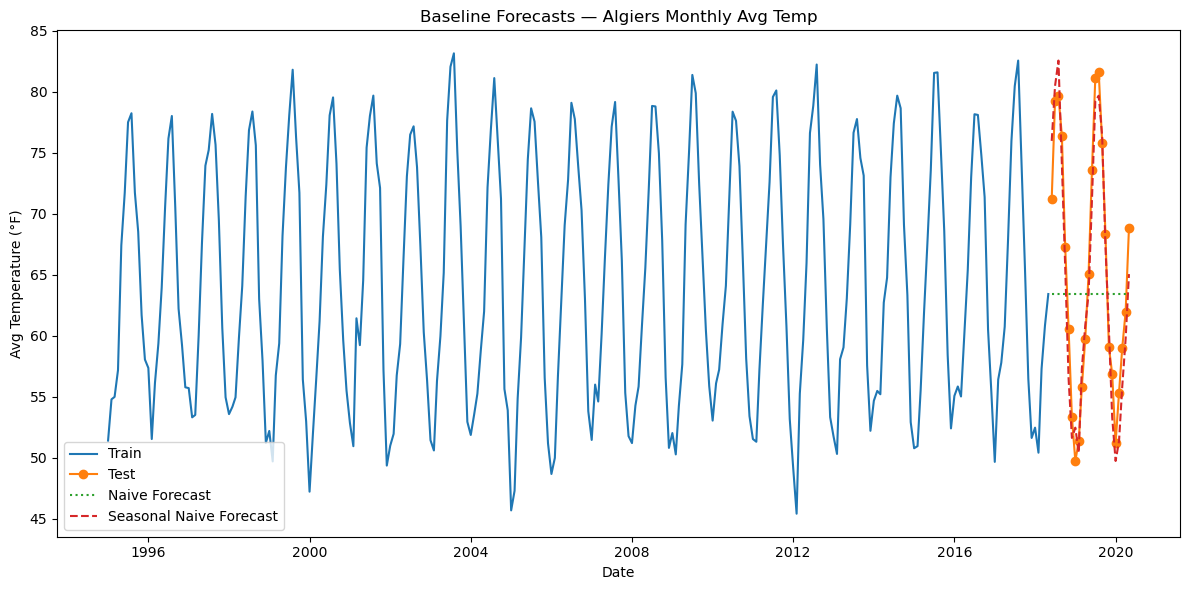

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(dates_train, y_train, label="Train")
plt.plot(dates_test, y_test, label="Test", marker="o")
plt.plot(dates_test, naive_forecast, label="Naive Forecast", linestyle=":")
plt.plot(dates_test, seasonal_naive_forecast, label="Seasonal Naive Forecast", linestyle="--")

plt.title("Baseline Forecasts — Algiers Monthly Avg Temp")
plt.xlabel("Date"); plt.ylabel("Avg Temperature (°F)")
plt.legend()
plt.tight_layout()
plt.show()

 SARIMA model

In [32]:
# Part 1: Import SARIMAX
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [33]:
# Part 2: Fit SARIMA model
# Parameters (p,d,q) × (P,D,Q,s)
# We'll start with a simple guess: (1,1,1) × (1,1,1,12)
sarima_model = SARIMAX(y_train,
                       order=(1,1,1),
                       seasonal_order=(1,1,1,12),
                       enforce_stationarity=False,
                       enforce_invertibility=False)

sarima_result = sarima_model.fit(disp=False)

print(sarima_result.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  281
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -559.151
Date:                            Sat, 13 Sep 2025   AIC                           1128.302
Time:                                    18:33:54   BIC                           1145.988
Sample:                                         0   HQIC                          1135.417
                                            - 281                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2917      0.057      5.113      0.000       0.180       0.403
ma.L1         -1.0000     65.327   

In [35]:
# Part 3: Forecast for the test period
sarima_forecast = sarima_result.get_forecast(steps=test_months)

# Get predicted values (already numpy array or Series)
sarima_pred = sarima_forecast.predicted_mean

# If it's a pandas Series, you can convert to numpy array explicitly
sarima_pred = np.array(sarima_pred)

# Get confidence intervals (for plotting)
sarima_ci = sarima_forecast.conf_int()

# Evaluate SARIMA
print("=== SARIMA Forecast Evaluation ===")
print("MAE :", round(mae(y_test, sarima_pred), 3))
print("RMSE:", round(rmse(y_test, sarima_pred), 3))
print("MAPE:", round(mape(y_test, sarima_pred), 3), "%")


=== SARIMA Forecast Evaluation ===
MAE : 1.376
RMSE: 1.617
MAPE: 2.197 %


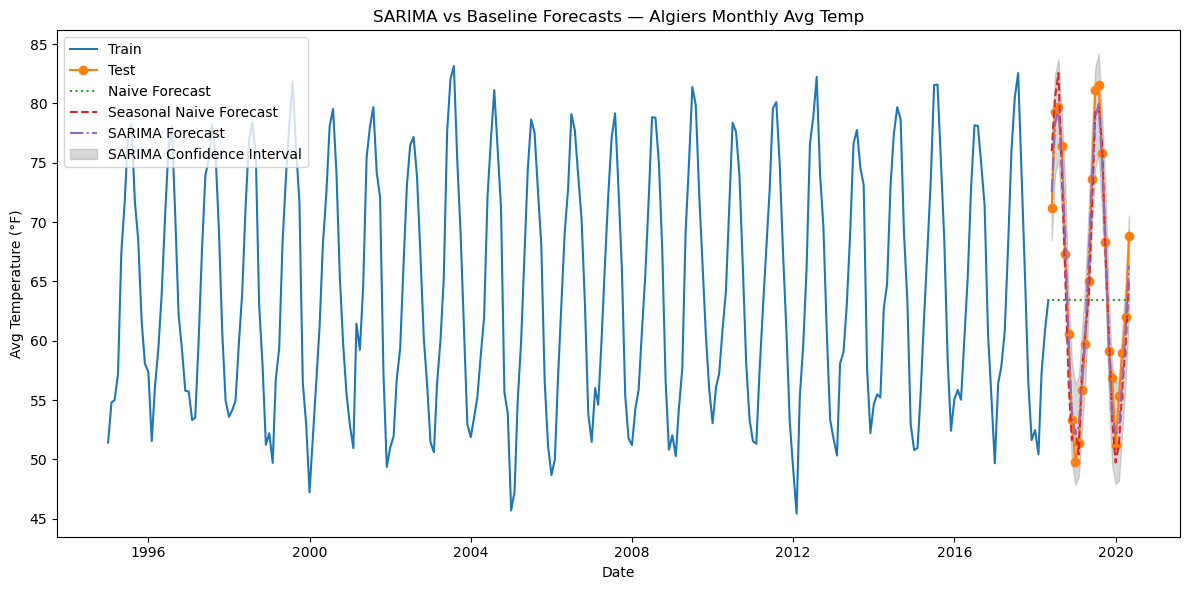

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))


plt.plot(dates_train, y_train, label="Train")
plt.plot(dates_test, y_test, label="Test", marker="o")
plt.plot(dates_test, naive_forecast, label="Naive Forecast", linestyle=":")
plt.plot(dates_test, seasonal_naive_forecast, label="Seasonal Naive Forecast", linestyle="--")
plt.plot(dates_test, sarima_pred, label="SARIMA Forecast", linestyle="-.")

# Confidence intervals 
plt.fill_between(dates_test,
                 sarima_ci[:, 0],   # lower bound
                 sarima_ci[:, 1],   # upper bound
                 color="gray", alpha=0.3, label="SARIMA Confidence Interval")


plt.title("SARIMA vs Baseline Forecasts — Algiers Monthly Avg Temp")
plt.xlabel("Date")
plt.ylabel("Avg Temperature (°F)")
plt.legend()
plt.tight_layout()
plt.show()